# 1·4·8·12·24시간 분석 구간 비교

입력의 집계 간격과 정상 참고 이력은 유지하고, **한 번에 판정하는 구간 길이만 변경**했다. 길이마다 정상 점수 통계와 경보 기준은 따로 보정했다.

기존 14일 모델과 평가셋은 보존했다. 이미 결과를 공개했던 반합성 평가셋을 재사용한 길이 비교이며, 새로운 독립 블라인드 평가나 실제 운영 장애 성능이 아니다.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/long_term_anomaly/intervals').is_dir())
sys.path.insert(0, str(ROOT / 'code'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from long_term_anomaly.intervals import report, score_frame
from long_term_anomaly.intervals.run import OUT
from long_term_anomaly.common import read_json
from long_term_anomaly.benchmark import load_split, CHANNELS
results, bank = report.context()
def show(fig):
    display(fig)
    plt.close(fig)

## 1. 무엇을 바꿨나?

| 항목 | 설정 |
|---|---|
| 정상 참고 이력 | 검토된 정상 28일, 시간당 1행 |
| 입력 집계 간격 | 1시간 유지 |
| 1회 분석 구간 | 1·4·8·12·24시간 선택 |
| 길이별 입력 행 수 | 각각 1·4·8·12·24행 |
| 경보 기준 | 길이마다 별도 보정 |
| 분석 도중 정상 기준 갱신 | 자동 갱신하지 않음 |

**1시간 모드는 1개 집계값을 정상 기준과 비교한다.** 1시간 안에서 서서히 악화되는 추세까지 보는 모델이 아니다. 그 수준을 보려면 집계를 1분이나 5분 단위로 바꿔야 한다.

PELT의 최소 구간은 12시간으로 유지했다. 따라서 1~12시간 입력은 변화점으로 나눌 수 없고, 24시간만 조건에 따라 둘로 나눌 수 있다. 존재하지 않는 이전/다음 배치를 함께 넣어 긴 추세를 본 것처럼 계산하지 않았다.

In [2]:
display(pd.DataFrame([{'분석 시간': h, '입력 행 수': h, '시간창': m.setting.window,
                       '편차 크기 시간창': m.setting.energy_window, 'PELT 최소 구간': m.setting.min_segment,
                       '적용 경보 기준': m.threshold}
                      for h, m in bank.models.items()]))

,분석 시간,입력 행 수,시간창,편차 크기 시간창,PELT 최소 구간,적용 경보 기준
0,1,1,1,1,12,1.522039
1,4,4,4,4,12,1.727335
2,8,8,8,8,12,1.704669
3,12,12,12,12,12,1.713290
4,24,24,12,24,12,1.881042


## 2. 길이별 성능 중앙값

각 시간의 원래 정답으로 시나리오별 지표를 계산한 뒤, 여섯 시나리오의 중앙값을 구했다. 네 지표는 높을수록, 오탐률은 낮을수록 좋다. **한 배치에 이상이 한 시간만 있어도 전체를 이상 정답으로 바꾸지 않았다.**

모든 길이에서 같은 관측 시간을 평가하므로 데이터 수 차이로 성능을 높이는 비교가 아니다.

,한 번에 분석하는 시간,Accuracy,Precision,Recall,F1,전체 오탐률,시나리오 최대 오탐률
0,1,82.36,38.83,10.30,16.28,3.08,3.18
1,4,85.40,65.28,27.60,38.95,3.05,3.54
2,8,88.54,74.54,45.12,55.69,3.04,3.40
3,12,90.06,77.41,55.27,63.48,3.20,3.67
4,24,91.93,80.79,65.43,71.53,3.01,3.44


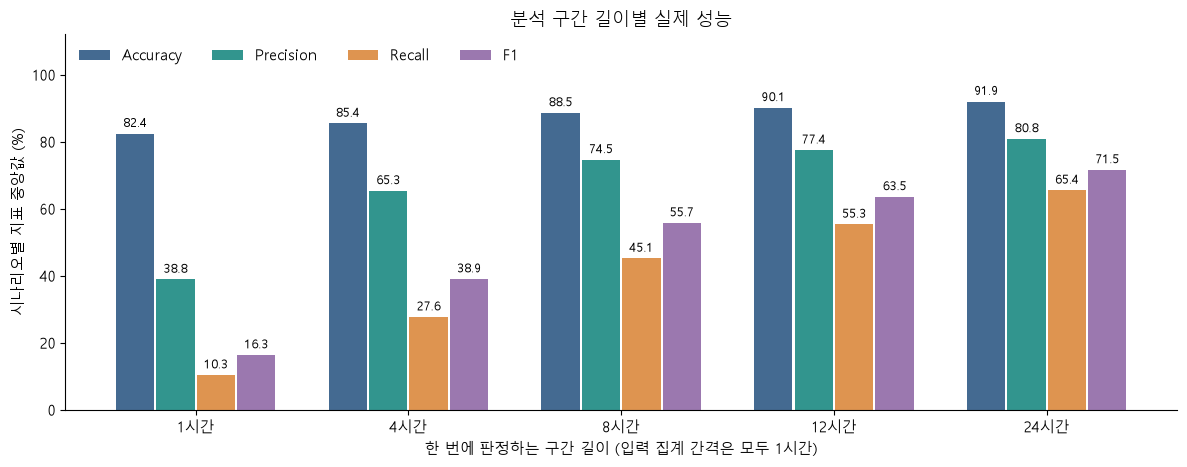

In [3]:
display(report.table('median'))
show(report.metric_plot('median'))

## 3. 전체 시간을 합치면 어떻게 달라지나?

위 중앙값은 모든 시나리오를 같은 비중으로 본 결과다. 아래 통합 지표는 모든 시간의 TP·FP·FN·TN을 합쳐 계산하므로 이상 시간이 긴 시나리오의 영향이 더 크다. **중앙값과 통합 지표를 구분해서 읽어야 한다.**

,한 번에 분석하는 시간,Accuracy,Precision,Recall,F1,전체 오탐률,시나리오 최대 오탐률
0,1,81.68,44.95,11.57,18.41,3.08,3.18
1,4,84.63,66.56,27.92,39.34,3.05,3.54
2,8,87.46,75.77,43.73,55.46,3.04,3.40
3,12,88.62,77.57,51.00,61.54,3.20,3.67
4,24,90.20,80.96,58.97,68.24,3.01,3.44


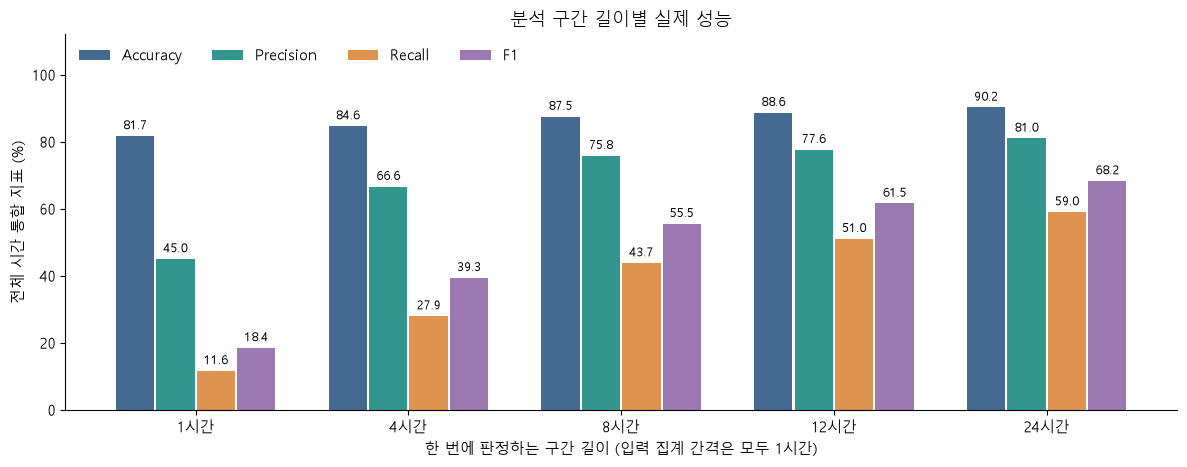

In [4]:
display(report.table('pooled'))
show(report.metric_plot('pooled'))

## 4. 오탐률과 경보 기준

기존 14일 경보 기준을 그대로 쓰지 않았다. 학습 정상 64사례로 점수 통계를 적합하고, 정상 보정 48사례 및 개발 데이터의 정상 시간으로 길이별 기준을 정했다. 최종 비교 점수로 기준을 다시 고르지 않았다.

전체 오탐률과 여섯 시나리오 중 최대 오탐률을 따로 보인다. 그림에는 성능 목표선이 아니라 실제 측정값만 표시했다.

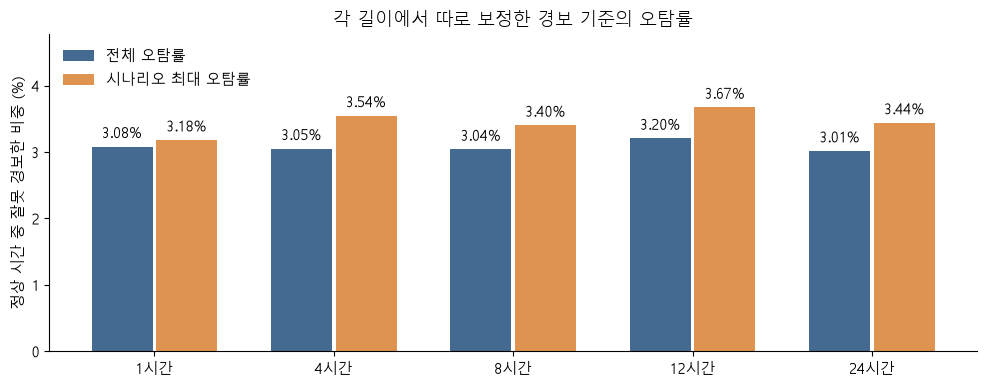

,분석 시간,정상 보정 하한 기준,최종 적용 기준
0,1,1.522039,1.522039
1,4,1.727335,1.727335
2,8,1.704669,1.704669
3,12,1.713290,1.713290
4,24,1.881042,1.881042


In [5]:
show(report.fpr_plot())
calibration = read_json(OUT / 'calibration.json')
display(pd.DataFrame([{'분석 시간': int(h), '정상 보정 하한 기준': c['normal_calibration_floor'],
                       '최종 적용 기준': bank.models[int(h)].threshold}
                      for h, c in calibration['models'].items()]))

## 5. 시나리오별 F1과 Recall

긴 입력이 어떤 시나리오에서 도움이 되는지 따로 확인한다. 짧은 구간은 한 시점의 큰 변화에 반응할 수 있지만 지속 여부를 판단할 정보가 적다. 긴 구간은 여러 시간을 함께 볼 수 있으나, 구간 내부의 짧은 이상이 평균에 희석될 수도 있다. 이 해석이 실제 표와 맞는지 확인해야 한다.

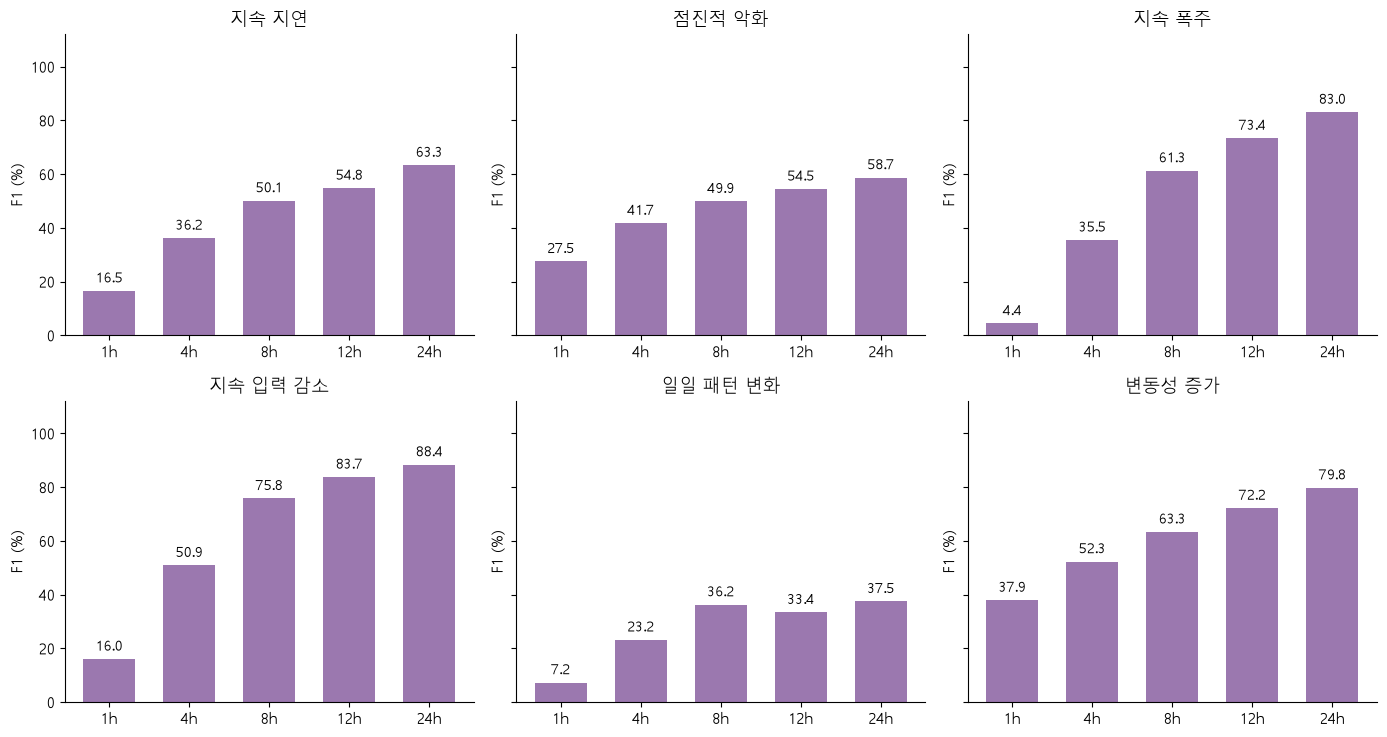

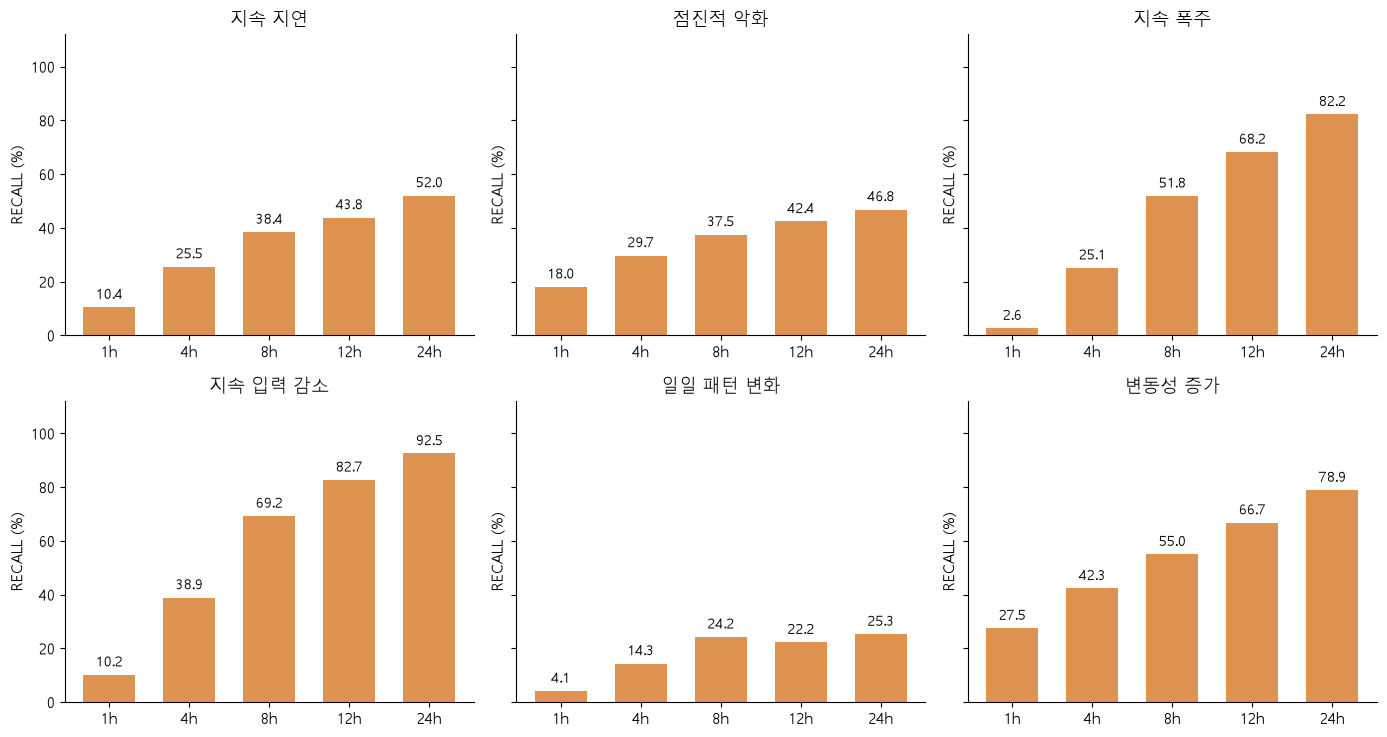

,analysis_hours,scenario,precision,recall,f1,false_positive_rate
0,1,daily_pattern_change,0.3141,0.0409,0.0724,0.0297
1,1,gradual_degradation,0.5818,0.1801,0.2751,0.0305
2,1,long_latency_shift,0.3984,0.1044,0.1655,0.0312
3,1,sustained_input_drop,0.3782,0.1015,0.1601,0.0305
4,1,sustained_overload,0.1359,0.0261,0.0438,0.0309
5,1,volatility_growth,0.6113,0.2748,0.3791,0.0318
6,4,daily_pattern_change,0.6047,0.1432,0.2315,0.0312
7,4,gradual_degradation,0.7021,0.2967,0.4171,0.0297
8,4,long_latency_shift,0.6210,0.2553,0.3618,0.0309
9,4,sustained_input_drop,0.7370,0.3886,0.5089,0.0254


In [6]:
show(report.scenario_plot('f1'))
show(report.scenario_plot('recall'))
scenario_metrics = pd.read_csv(OUT / 'scenario_metrics.csv')
display(scenario_metrics[['analysis_hours','scenario','precision','recall','f1','false_positive_rate']].round(4))

## 6. 같은 사례에서 점수가 어떻게 달라지나?

파일 순서상 첫 번째 이상 주입 사례를 그대로 비교한다. 잘 탐지한 사례를 골라내지 않았다. 주황 배경은 주입한 이상 구간이다.

세로값은 **점수 ÷ 해당 길이의 실제 경보 기준**이다. 점선 1을 넘으면 경보다. 장애 확률이나 성능 목표선은 아니다.

이 그림은 각 배치가 끝난 뒤 얻은 점수를 한 시계열에 모아 그린 것이다. 24시간 모드에서 하루가 지나기 전에 하루 전체를 판정했다고 해석하면 안 된다.

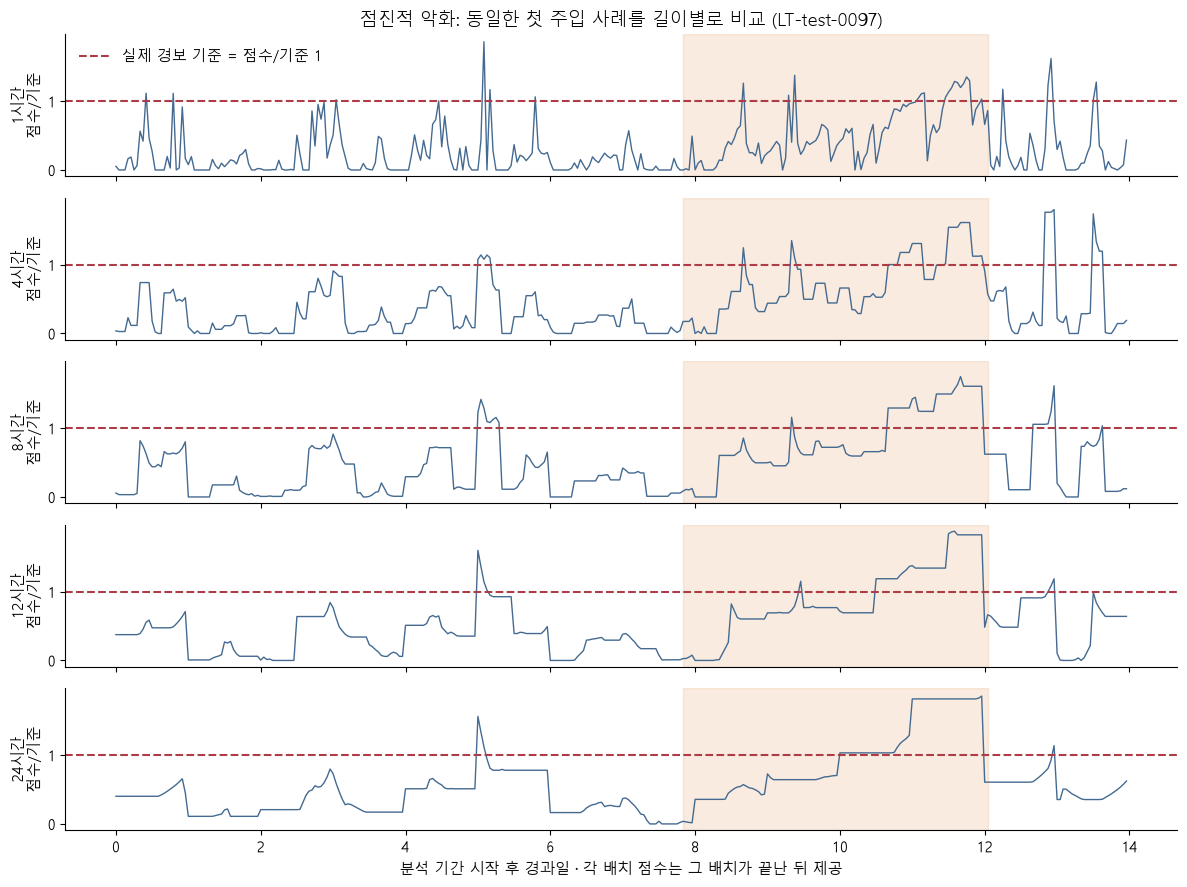

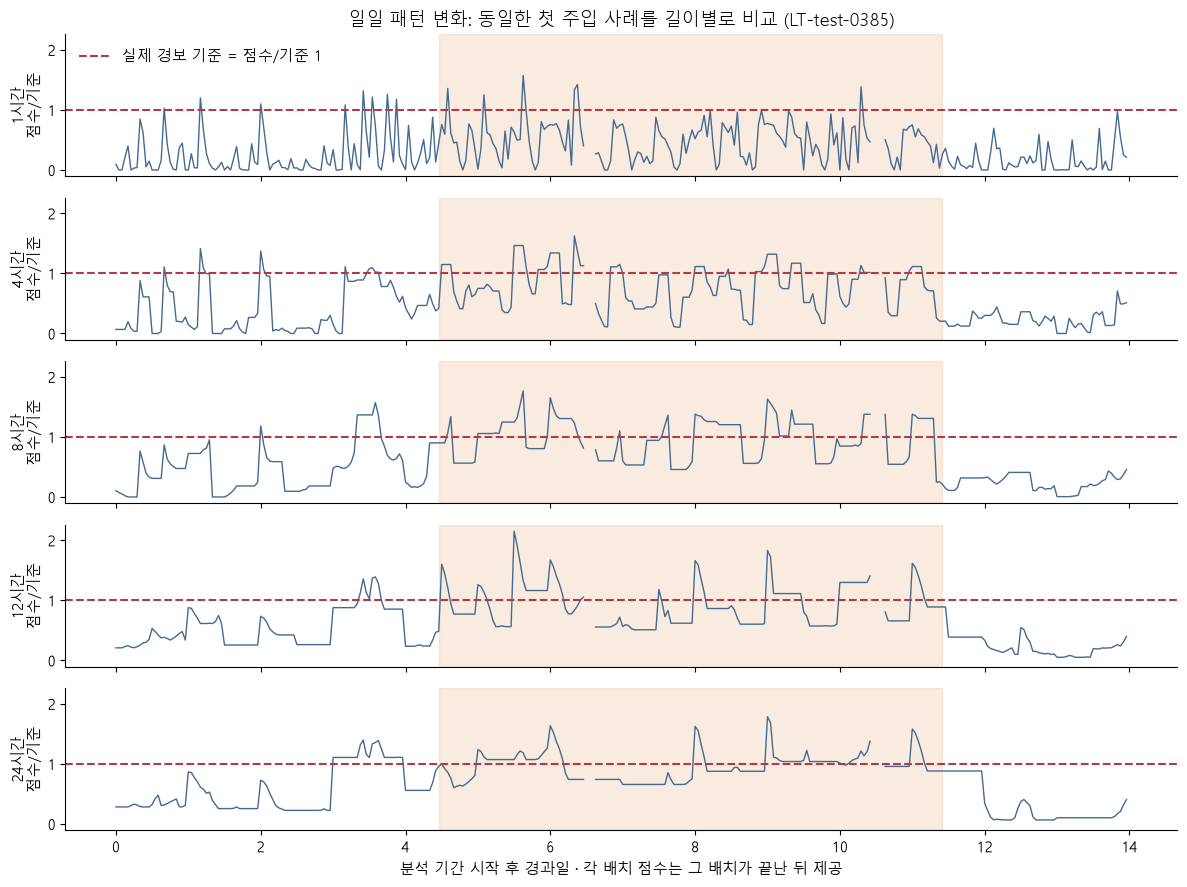

In [7]:
show(report.timeline('gradual_degradation'))
show(report.timeline('daily_pattern_change'))

## 7. 입력 길이를 직접 바꾸는 예

다음 셀의 `analysis_hours`만 1·4·8·12·24 중 하나로 바꾸면 된다. 정상 참고 구간은 같은 것을 사용하고, 이번 분석 데이터만 선택한 길이만큼 넣는다.

예시는 API 사용법을 보이기 위해 기존 평가 입력의 첫 사례를 사용한다. 실서비스에서는 백엔드가 만든 같은 형식의 시간당 집계를 전달하면 된다. 정답 파일은 필요 없다.

In [8]:
data = load_split('test', with_truth=False)
example = pd.DataFrame(data['X'][0], columns=CHANNELS)
example['case_id'] = str(data['case_id'][0])
example['timestamp'] = pd.date_range(pd.Timestamp(int(data['start_ns'][0])), periods=len(example), freq='h')
example['collection_observed'] = data['collection_observed'][0]
example['latency_available'] = data['latency_available'][0]
reference = bank.prepare_reference(example.iloc[:672])

analysis_hours = 4  # 1, 4, 8, 12, 24 중 선택
current_batch = example.iloc[672:672 + analysis_hours]
output = bank.predict_batch(reference, current_batch, analysis_hours=analysis_hours)
display(output[['timestamp','analysis_hours','score','threshold','is_anomaly','assessable','available_at']])

,timestamp,analysis_hours,score,threshold,is_anomaly,assessable,available_at
0,2030-01-29 07:00:00,4,0.197933,1.727335,False,True,2030-01-29 11:00:00
1,2030-01-29 08:00:00,4,0.197933,1.727335,False,True,2030-01-29 11:00:00
2,2030-01-29 09:00:00,4,0.197933,1.727335,False,True,2030-01-29 11:00:00
3,2030-01-29 10:00:00,4,0.197933,1.727335,False,True,2030-01-29 11:00:00


`reference`는 28일 정상 기준에서 구한 시간대 패턴·변동 폭 등을 메모리에 보관한다. 배치마다 28일 데이터를 다시 전송하거나 정상 기준을 다시 적합할 필요는 없다. 다른 Adapter+Process의 참고 기준을 섞으면 안 된다.

`available_at`은 입력한 배치가 끝나는 시각이다. 예를 들어 00~04시의 네 행을 입력하면 04시 이후에 결과를 제공한다. 실제 CPU 처리 시간을 측정한 값은 아니다.

## 8. 검증과 해석 범위

- 원본·기존 14일 모델·기존 노트북·평가셋의 해시 보존 확인
- 다음 배치를 변경해도 앞선 배치 점수가 바뀌지 않는 테스트
- 시간대 기준을 배치마다 처음 시각으로 잘못 되돌리지 않는 정렬 테스트
- 길이마다 같은 관측 시간을 평가하고, 수집 결측을 정상/0건으로 처리하지 않음
- 길이별 API 점수와 저장된 비교 점수의 재현 확인
- 기존 평가셋 재사용이므로 새로운 독립 평가를 주장하지 않음

이 평가셋은 3~7일 지속되는 이상 중심이다. 여기서 성능이 높은 길이가 짧은 장애나 모든 운영 환경에서도 최적이라는 뜻은 아니다. 실제 원본에 28일 연속 정상 이력이 충분히 있다는 뜻도 아니다.

In [9]:
validation = read_json(OUT / 'validation.json')
display(pd.DataFrame([{'검증': name, '결과': passed} for name, passed in validation['checks'].items()]))
print('모든 길이에서 평가한 관측 시간:', validation['assessed_hours_per_horizon'])

,검증,결과
0,legacy_model_code_notebook_results_preserved,True
1,original_frozen_benchmark_unchanged,True
2,all_three_raw_process_sources_preserved,True
3,all_horizons_use_exactly_the_same_observed_hours,True
4,all_pooled_and_scenario_metrics_independently_...,True
5,thirty_full_API_replays_match_saved_scores_wit...,True
6,horizon_specific_thresholds_match_saved_models,True
7,no_new_blind_test_claim,True


모든 길이에서 평가한 관측 시간: 192178


## 파일과 실행 방법

- 사용 모델: `reports/long_term_anomaly/intervals/models.joblib`
- 길이별 수치: `reports/long_term_anomaly/intervals/comparison.csv`
- 시나리오별 수치: `reports/long_term_anomaly/intervals/scenario_metrics.csv`
- 코드/API/CSV 명령: 같은 폴더의 `README.md`

```python
from long_term_anomaly.intervals import load_bank
bank = load_bank('reports/long_term_anomaly/intervals/models.joblib')
reference = bank.prepare_reference(normal_history_28days)
result = bank.predict_batch(reference, current_4hours, analysis_hours=4)
```

모델 적합은 정상 데이터만 사용했고, 기준 보정에는 개발 정답으로 식별한 정상 시간도 사용했다. 완전히 라벨 없는 전체 절차라고 주장하지 않는다.